#### STUDENT PERFORMANCE INDICATOR

## Life cycle of Machine Learning Project

Understanding the problem statement.

Data Collection.

Data Checks to perform.

Exploratory Data Analysis.

Data Pre-processing.

Model Training.

Choose best model.


#### 1) Problem Statement

This project understand how the students performance(test score) is affected by other variable such as Gender,Ethnicity,Parental level of Education, Lunch and Test Preparation Course.

#### 2) Data Collection

Dataset Source :https://www.kaggle.com/datasets/spscientist/students-performance-in-exams

Dataset contains 8 columns and 1000 rows.

#### 2.1) Import data and Required Packages

Importing Pandas,Numpy,matplotlib,Seaborn and Warnings Library.

In [ ]:
!pip install ipykernel

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

#### Import the CSV Data as Pandas DataFrame. 

In [3]:
df = pd.read_csv("data/study.csv", sep="\t")

In [4]:
df.head(),df.shape

(   gender race/ethnicity parental level of education         lunch  \
 0  female        group B           bachelor's degree      standard   
 1  female        group C                some college      standard   
 2  female        group B             master's degree      standard   
 3    male        group A          associate's degree  free/reduced   
 4    male        group C                some college      standard   
 
   test preparation course  math score  reading score  writing score  
 0                    none          72             72             74  
 1               completed          69             90             88  
 2                    none          90             95             93  
 3                    none          47             57             44  
 4                    none          76             78             75  ,
 (1000, 8))

#### Creating a DataFrame.

In [5]:
df = pd.DataFrame(df)

df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


#### 2.2) DataSet Information.

#### 3.1) Data Checks to perform
check missing values

check duplicates

check data types

check the number of unique values of each column

check statistics of dataset

check various categories present in the different categorical column.

In [6]:
df.isna().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

#### Observations: There is no missing/Null values in the dataset.

#### Check Duplicates Values.

In [7]:
df.duplicated().sum()

np.int64(0)

#### Observations: There are no duplicates values in the dataset.

#### 3.3) Check Null and data Types.

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 103.5 KB


#### 3.4) Checking the Number of unique values in each columns.

In [9]:
df.nunique() # 'nunique()'--> No of unique values.

gender                          2
race/ethnicity                  5
parental level of education     6
lunch                           2
test preparation course         2
math score                     81
reading score                  72
writing score                  77
dtype: int64

In [10]:
print("Categories in 'gender' variable :  ",end=" ")
print(df['gender'].unique())

print("Categories in 'race/ethnicity' variable :  ",end=" ")
print(df['race/ethnicity'].unique())

print("Categories in 'parental level of education' variable :  ",end=" ")
print(df['parental level of education'].unique())

print("Categories in 'lunch' variable :  ",end=" ")
print(df['lunch'].unique())

print("Categories in 'test preparation course' variable :  ",end=" ")
print(df['test preparation course'].unique())

Categories in 'gender' variable :   <ArrowStringArray>
['female', 'male']
Length: 2, dtype: str
Categories in 'race/ethnicity' variable :   <ArrowStringArray>
['group B', 'group C', 'group A', 'group D', 'group E']
Length: 5, dtype: str
Categories in 'parental level of education' variable :   <ArrowStringArray>
[ 'bachelor's degree',       'some college',    'master's degree',
 'associate's degree',        'high school',   'some high school']
Length: 6, dtype: str
Categories in 'lunch' variable :   <ArrowStringArray>
['standard', 'free/reduced']
Length: 2, dtype: str
Categories in 'test preparation course' variable :   <ArrowStringArray>
['none', 'completed']
Length: 2, dtype: str


In [11]:
df['gender'].unique()

<ArrowStringArray>
['female', 'male']
Length: 2, dtype: str

#### 3.5) Check statistics of data.

In [12]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


#### Insight
From above description of numerical data, all means are very close to each other-between 66 to 68.05.

All Standard Deviations are also close between 14.6 to 15.20.

While there is min score is 0 for maths, for reading score and writing score it is much higher.

#### 3.6) Check various categories present in the different categorical column.

In [13]:
## Define Numerical and Categorical columns.

numeric_features=[feature for feature in df.columns if df[feature].dtype!='str']
categorical_features=[feature for feature in df.columns if df[feature].dtype=='str']

# Print Columns
print('We have {} numerical features :{}'.format(len(numeric_features),numeric_features))

print('We have {} categorical features :{}'.format(len(categorical_features),categorical_features))

We have 3 numerical features :['math score', 'reading score', 'writing score']
We have 5 categorical features :['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course']


#### Adding new columns ['Total Score'] inplace of all score's columns.

#### And also determining the 'Average'.

In [14]:
df['total_score']=df['math score']+df['reading score']+df['writing score']

df['Average']=df['total_score']/3

df.head()


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,total_score,Average
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667
1,female,group C,some college,standard,completed,69,90,88,247,82.333333
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333
4,male,group C,some college,standard,none,76,78,75,229,76.333333


In [15]:
df[df['reading score']==100]['Average'].count()

np.int64(17)

In [16]:
df.shape

(1000, 10)

#### Total number of students got full_marks in different different score.

In [17]:
reading_full=df[df['reading score']==100]['Average'].count()
writing_full=df[df['writing score']==100]['Average'].count()
math_full=df[df['math score']==100]['Average'].count()

print(f"Number of students with full marks in reading : {reading_full}")
print(f"Number of students with full marks in writing : {writing_full}")
print(f"Number of students with full marks in maths : {math_full}")

Number of students with full marks in reading : 17
Number of students with full marks in writing : 14
Number of students with full marks in maths : 7


#### Total number of students got less than 20 marks in different different score.

In [18]:
reading_less_20=df[df['reading score']<=20]['Average'].count()
writing_less_20=df[df['writing score']<=20]['Average'].count()
math_less_20=df[df['math score']<=20]['Average'].count()

print(f"Number of students with less than 20 marks in reading : {reading_less_20}")
print(f"Number of students with less than 20 marks in writing : {writing_less_20}")
print(f"Number of students with less than 20 marks in maths : {math_less_20}")

Number of students with less than 20 marks in reading : 1
Number of students with less than 20 marks in writing : 3
Number of students with less than 20 marks in maths : 4


#### Insights:

From above values we get the students have performed the worst in Maths.

Best performance is in Reading and  Writing Sections.

#### 4) Exploring Data Analysis (Visualisation)

#### 4.1) Visualize average score distribution to make some conclusions.

Histogram

kernel distribution Function [KDE]

#### 4.1.1) Histogram and KDE.

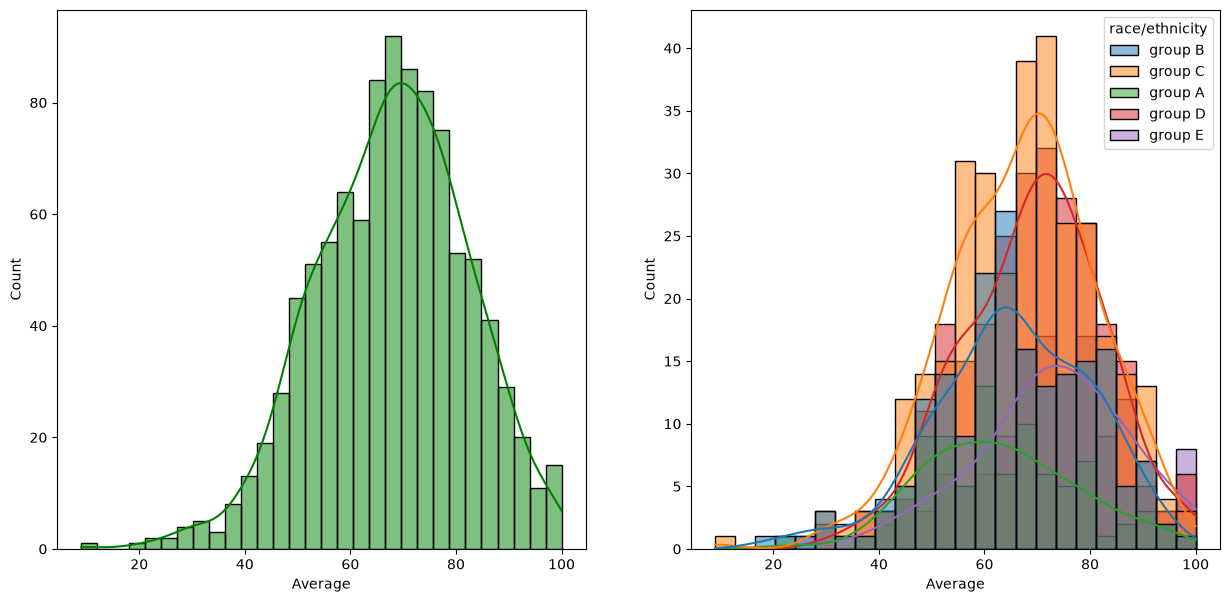

In [ ]:
## Plotting KDE Graph and Histogram for 'Average' Marks.

fig, axs=plt.subplots(1,2,figsize=(15,7))
plt.subplot(121)
sns.histplot(data=df,x='Average',bins=30,kde=True,color='g')
plt.subplot(122)
sns.histplot(data=df,x='Average',kde=True,hue='gender')
plt.show()

#### Insights:
Female students are performs well than male students.

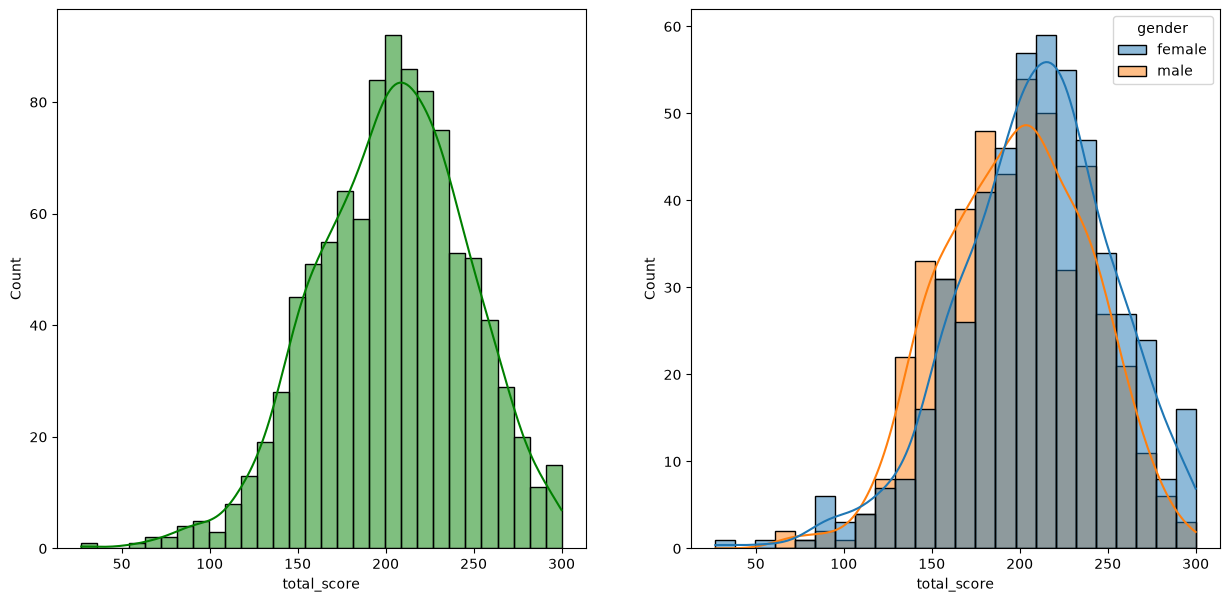

In [25]:
## Plotting KDE Graph and Histogram for 'Total_score' Marks.

fig, axs=plt.subplots(1,2,figsize=(15,7))
plt.subplot(121)
sns.histplot(data=df,x='total_score',bins=30,kde=True,color='g')
plt.subplot(122)
sns.histplot(data=df,x='total_score',kde=True,hue='gender')
plt.show()

#### Insights:
Female students are performs well than male students.